Assignment 5
Name: Muyuan Ma
DS 3000

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# load the dataframe
aviation_df = pd.read_csv('aviation_data.csv')

In [3]:
# see each column's name
print(aviation_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85627 entries, 0 to 85626
Data columns (total 32 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Event Id                  85627 non-null  object
 1    Investigation Type       85627 non-null  object
 2    Accident Number          85627 non-null  object
 3    Event Date               85627 non-null  object
 4    Location                 85627 non-null  object
 5    Country                  85627 non-null  object
 6    Latitude                 85627 non-null  object
 7    Longitude                85627 non-null  object
 8    Airport Code             85627 non-null  object
 9    Airport Name             85627 non-null  object
 10   Injury Severity          85627 non-null  object
 11   Aircraft Damage          85627 non-null  object
 12   Aircraft Category        85627 non-null  object
 13   Registration Number      85627 non-null  object
 14   Make                 

In [4]:
# removing white space for each assigned columns
aviation_df.columns = aviation_df.columns.str.strip()

In [5]:
print(aviation_df.info())
# extract the assigned columns
new_aviation_df = aviation_df.filter(items=['Broad Phase of Flight', 'Total Uninjured', 'Total Minor Injuries',
                                            'Total Serious Injuries', 'Total Fatal Injuries', 'Air Carrier',
                                            'Make', 'Model', 'Aircraft Category', 'Aircraft Damage', 
                                            'Injury Severity', 'Country', 'Event Date', 'Investigation Type', 'Event Id'])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85627 entries, 0 to 85626
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Event Id                85627 non-null  object
 1   Investigation Type      85627 non-null  object
 2   Accident Number         85627 non-null  object
 3   Event Date              85627 non-null  object
 4   Location                85627 non-null  object
 5   Country                 85627 non-null  object
 6   Latitude                85627 non-null  object
 7   Longitude               85627 non-null  object
 8   Airport Code            85627 non-null  object
 9   Airport Name            85627 non-null  object
 10  Injury Severity         85627 non-null  object
 11  Aircraft Damage         85627 non-null  object
 12  Aircraft Category       85627 non-null  object
 13  Registration Number     85627 non-null  object
 14  Make                    85627 non-null  object
 15  Mo

In [6]:
# remove white spaces for each data in each column
for columns in new_aviation_df:
    new_aviation_df[columns] = new_aviation_df[columns].str.strip()

In [7]:
# change all empty string to null value
for columns in new_aviation_df:
    new_aviation_df[columns] = new_aviation_df[columns].replace('', np.nan)

In [8]:
# check the data type of the new dataframe
print(new_aviation_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85627 entries, 0 to 85626
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Broad Phase of Flight   78995 non-null  object
 1   Total Uninjured         70455 non-null  object
 2   Total Minor Injuries    55787 non-null  object
 3   Total Serious Injuries  54550 non-null  object
 4   Total Fatal Injuries    57297 non-null  object
 5   Air Carrier             4270 non-null   object
 6   Make                    85559 non-null  object
 7   Model                   85531 non-null  object
 8   Aircraft Category       28889 non-null  object
 9   Aircraft Damage         82705 non-null  object
 10  Injury Severity         85627 non-null  object
 11  Country                 85120 non-null  object
 12  Event Date              85627 non-null  object
 13  Investigation Type      85616 non-null  object
 14  Event Id                85627 non-null  object
dtypes:

In [9]:
# check the dimension of the new dataframe
print(new_aviation_df.shape)

(85627, 15)


In [10]:
# check the amount of null values in each columns
print(new_aviation_df.isnull().sum())

Broad Phase of Flight      6632
Total Uninjured           15172
Total Minor Injuries      29840
Total Serious Injuries    31077
Total Fatal Injuries      28330
Air Carrier               81357
Make                         68
Model                        96
Aircraft Category         56738
Aircraft Damage            2922
Injury Severity               0
Country                     507
Event Date                    0
Investigation Type           11
Event Id                      0
dtype: int64


In [11]:
# check the number of null values for each row
print(new_aviation_df.isnull().sum(axis=1).sort_values(ascending = False))

26821    11
19573    10
11845    10
18065    10
14536    10
         ..
82366     0
85237     0
82231     0
82232     0
82975     0
Length: 85627, dtype: int64


In [12]:
# delete the rows that has 5 or more types of data missing(missing 50% data)
new_aviation_df = new_aviation_df[new_aviation_df.isnull().sum(axis = 1) < 5]

In [13]:
# check the new dimension of the new updated dataframe
print(new_aviation_df.shape)

(71752, 15)


In [14]:
# check the number of null number of the new updated dataframe for each type
print(new_aviation_df.isnull().sum())

Broad Phase of Flight      1640
Total Uninjured            8239
Total Minor Injuries      17469
Total Serious Injuries    18413
Total Fatal Injuries      17983
Air Carrier               67559
Make                          9
Model                        23
Aircraft Category         47184
Aircraft Damage            1598
Injury Severity               0
Country                     475
Event Date                    0
Investigation Type            0
Event Id                      0
dtype: int64


In [15]:
# check the frequency of each data exist in Broad Phase of Flight
print(new_aviation_df['Broad Phase of Flight'].value_counts(dropna=False))

LANDING        18970
TAKEOFF        14808
CRUISE          9761
MANEUVERING     9293
APPROACH        7326
TAXI            2219
CLIMB           2083
DESCENT         2065
NaN             1640
GO-AROUND       1543
STANDING        1166
UNKNOWN          730
OTHER            148
Name: Broad Phase of Flight, dtype: int64


The above data shows that most accident happened when landing. So replace all missing type with LANDING

In [16]:
# impute all the null value with the mode value LANDING
new_aviation_df.loc[new_aviation_df['Broad Phase of Flight'].isna(), 'Broad Phase of Flight'] = 'LANDING'

In [17]:
# see the updated Broad Phase of Flight column
print(new_aviation_df['Broad Phase of Flight'].value_counts(dropna=False))

LANDING        20610
TAKEOFF        14808
CRUISE          9761
MANEUVERING     9293
APPROACH        7326
TAXI            2219
CLIMB           2083
DESCENT         2065
GO-AROUND       1543
STANDING        1166
UNKNOWN          730
OTHER            148
Name: Broad Phase of Flight, dtype: int64


In [18]:
# check the frequency of each data exist in Total Uninjured
print(new_aviation_df['Total Uninjured'].value_counts(dropna=False))

1      21408
0      19108
2      13102
NaN     8239
3       3631
       ...  
287        1
230        1
386        1
283        1
393        1
Name: Total Uninjured, Length: 354, dtype: int64


In [19]:
# impute all null data of Total Uninjured with 1, which is the mode value
new_aviation_df.loc[new_aviation_df['Total Uninjured'].isna(), 'Total Uninjured'] = 1

In [20]:
# check the frequency, and see which is the mode value for Total Minor Injuries column
print(new_aviation_df['Total Minor Injuries'].value_counts(dropna=False))

0      40024
NaN    17469
1       9276
2       3393
3        783
       ...  
53         1
67         1
137        1
161        1
29         1
Name: Total Minor Injuries, Length: 64, dtype: int64


In [21]:
# impute all the null value with the mode value 0
new_aviation_df.loc[new_aviation_df['Total Minor Injuries'].isna(), 'Total Minor Injuries'] = 0

In [22]:
# check the mode value for the Total Serious Injuries cloumn
print(new_aviation_df['Total Serious Injuries'].value_counts(dropna=False))

0      42628
NaN    18413
1       7836
2       2045
3        476
4        189
5         58
6         25
7         21
8          9
9          7
13         6
10         6
26         4
50         3
17         2
59         2
12         2
15         2
16         2
14         1
81         1
44         1
106        1
60         1
47         1
21         1
22         1
18         1
45         1
39         1
111        1
27         1
66         1
19         1
28         1
Name: Total Serious Injuries, dtype: int64


In [23]:
# impute all the null value with the mode value 0
new_aviation_df.loc[new_aviation_df['Total Serious Injuries'].isna(), 'Total Serious Injuries'] = 0

In [24]:
# check the mode value in Total Fatal Injuries column
print(new_aviation_df['Total Fatal Injuries'].value_counts(dropna=False))

0      40059
NaN    17983
1       7017
2       3904
3       1202
       ...  
60         1
19         1
88         1
169        1
78         1
Name: Total Fatal Injuries, Length: 98, dtype: int64


In [25]:
# impute all the null value with the mode value 0
new_aviation_df.loc[new_aviation_df['Total Fatal Injuries'].isna(), 'Total Fatal Injuries'] = 0

In [26]:
# check the mode value in Air Carrier column
print(new_aviation_df['Air Carrier'].value_counts(dropna=False))

NaN                                                  67559
UNITED AIRLINES                                         48
AMERICAN AIRLINES                                       41
SOUTHWEST AIRLINES CO                                   33
Delta Air Lines                                         30
                                                     ...  
Corporate Flight International                           1
Helitrans Company Inc.                                   1
Island Air (DBA: Island Air Service)                     1
Mesaba Airlines (DBA: Northwest Airlines Airlink)        1
ROCKY MOUNTAIN HELICOPTERS IN                            1
Name: Air Carrier, Length: 2965, dtype: int64


Because the number of empty value is much more higher than any recorded amount of air carrier's value, 
In order make the data more real and not count lots of data one one company, 
I decide to give these missing data the value of unknown

In [27]:
# impute all the null value with unknown
new_aviation_df.loc[new_aviation_df['Air Carrier'].isna(), 'Air Carrier'] = 'Unknown'

In [28]:
# check the mode value in column Make
print(new_aviation_df['Make'].value_counts(dropna=False))

CESSNA           17237
PIPER             9499
Cessna            5696
BEECH             3127
Piper             2951
                 ...  
BINGHAM CHUCK        1
GALLAGHER            1
PIONTKOWSKI          1
Davenport            1
SONS MUSTANG         1
Name: Make, Length: 6679, dtype: int64


In [29]:
# impute all the null value with CESSNA since it is the mode value, 
# and the amount of null value is much smaller than the amount of mode value
new_aviation_df.loc[new_aviation_df['Make'].isna(), 'Make'] = 'CESSNA'

In [30]:
# turn all Cessna to CESSNA
new_aviation_df.loc[new_aviation_df['Make'] == 'Cessna', 'Make'] = 'CESSNA'

In [31]:
# check the mode value is added up and whether Cessna has become CESSNA
print(new_aviation_df['Make'].value_counts(dropna=False))

CESSNA           22942
PIPER             9499
BEECH             3127
Piper             2951
BELL              1542
                 ...  
BINGHAM CHUCK        1
GALLAGHER            1
PIONTKOWSKI          1
Davenport            1
SONS MUSTANG         1
Name: Make, Length: 6677, dtype: int64


In [32]:
# check the mode value in column Model
print(new_aviation_df['Model'].value_counts(dropna=False))

152                   2159
172                   1496
172N                   987
PA-28-140              806
150                    743
                      ... 
Tango 2                  1
Zenair CH 701            1
YMF-FSC                  1
R22 Mariner              1
WCS-222 (BELL 47G)       1
Name: Model, Length: 10335, dtype: int64


In [33]:
# impute all the null value with 152, since it's the mode value and 
# its amount is much bigger than the amount of null value
new_aviation_df.loc[new_aviation_df['Model'].isna(), 'Model'] = '152'

In [34]:
# check whether the mode value has added up
print(new_aviation_df['Model'].value_counts(dropna=False))

152                   2182
172                   1496
172N                   987
PA-28-140              806
150                    743
                      ... 
Beaver DHC-2 MK.1        1
Falcon 20D               1
HXB                      1
PA-22 (20)               1
WCS-222 (BELL 47G)       1
Name: Model, Length: 10334, dtype: int64


In [35]:
# check the mode value in column Aircraft Category
print(new_aviation_df['Aircraft Category'].value_counts(dropna=False))

NaN                  47184
Airplane             21114
Helicopter            2494
Glider                 426
Balloon                194
Weight-Shift            97
Gyrocraft               82
Powered Parachute       63
Gyroplane               56
Ultralight              30
Unknown                  5
Blimp                    4
Powered-Lift             2
Rocket                   1
Name: Aircraft Category, dtype: int64


Because the amount of unknown value is much higher than the mode value, it's unfair
to attribute all accident to airplane accident. So put in unknown category.

In [36]:
# impute all the null value with Unknown
new_aviation_df.loc[new_aviation_df['Aircraft Category'].isna(), 'Aircraft Category'] = 'Unknown'

In [37]:
# check whether the Unknown category has added up
print(new_aviation_df['Aircraft Category'].value_counts(dropna=False))

Unknown              47189
Airplane             21114
Helicopter            2494
Glider                 426
Balloon                194
Weight-Shift            97
Gyrocraft               82
Powered Parachute       63
Gyroplane               56
Ultralight              30
Blimp                    4
Powered-Lift             2
Rocket                   1
Name: Aircraft Category, dtype: int64


In [38]:
# check the mode value in column
print(new_aviation_df['Aircraft Damage'].value_counts(dropna=False))

Substantial    52670
Destroyed      15399
Minor           2085
NaN             1598
Name: Aircraft Damage, dtype: int64


In [39]:
# impute all the null value with Substantial, which is the mode value. 
# That's because the amount of null value is much smaller than the mode value.
new_aviation_df.loc[new_aviation_df['Aircraft Damage'].isna(), 'Aircraft Damage'] = 'Substantial'

In [40]:
# check the whether the mode value has added up
print(new_aviation_df['Aircraft Damage'].value_counts(dropna=False))

Substantial    54268
Destroyed      15399
Minor           2085
Name: Aircraft Damage, dtype: int64


In [41]:
# check the mode value in column Country
print(new_aviation_df['Country'].value_counts(dropna=False))

United States    69133
NaN                475
Brazil             145
Bahamas            145
Mexico             144
                 ...  
Libya                1
New Caledonia        1
Comoros              1
Estonia              1
Anguilla             1
Name: Country, Length: 158, dtype: int64


In [42]:
# impute all the null value with 
new_aviation_df.loc[new_aviation_df['Country'].isna(), 'Country'] = 'United States'

In [43]:
# check whether the mode value has added up
print(new_aviation_df['Country'].value_counts(dropna=False))

United States            69608
Bahamas                    145
Brazil                     145
Mexico                     144
Canada                     138
                         ...  
Sao Tome And Principe        1
Vanuatu                      1
Libya                        1
Comoros                      1
Anguilla                     1
Name: Country, Length: 157, dtype: int64


In [44]:
# finally check whether all null value has been cleared
print(new_aviation_df.isnull().sum())

Broad Phase of Flight     0
Total Uninjured           0
Total Minor Injuries      0
Total Serious Injuries    0
Total Fatal Injuries      0
Air Carrier               0
Make                      0
Model                     0
Aircraft Category         0
Aircraft Damage           0
Injury Severity           0
Country                   0
Event Date                0
Investigation Type        0
Event Id                  0
dtype: int64


Change all qualitative data's data type to the correct type

In [45]:
# change Broad Phase of Flight data type to category
new_aviation_df['Broad Phase of Flight'] = new_aviation_df['Broad Phase of Flight'].astype('category')

In [46]:
# change Air Carrier data type to category
new_aviation_df['Air Carrier'] = new_aviation_df['Air Carrier'].astype('category')

In [47]:
# change Make data type to category
new_aviation_df['Make'] = new_aviation_df['Make'].astype('category')

In [48]:
# change Model data type to category
new_aviation_df['Model'] = new_aviation_df['Model'].astype('category')

In [49]:
# change Aircraft Category data type to category
new_aviation_df['Aircraft Category'] = new_aviation_df['Aircraft Category'].astype('category')

In [50]:
# change Aircraft Damage data type to category
new_aviation_df['Aircraft Damage'] = new_aviation_df['Aircraft Damage'].astype('category')

In [51]:
# change Injury Severity data type to category
new_aviation_df['Injury Severity'] = new_aviation_df['Injury Severity'].astype('category')

In [52]:
# change Country data type to category
new_aviation_df['Country'] = new_aviation_df['Country'].astype('category')

In [53]:
# change Investigation Type data type to category
new_aviation_df['Investigation Type'] = new_aviation_df['Investigation Type'].astype('category')

In [54]:
# change Event Date data type to date
new_aviation_df['Event Date'] = pd.to_datetime(new_aviation_df['Event Date'], errors = 'coerce')

In [55]:
# change Event Id to string
new_aviation_df['Event Id'] = new_aviation_df['Event Id'].astype('string')

Change all qualitative data's data type to the correct type

In [56]:
# change Total Uninjured
new_aviation_df['Total Uninjured'] = new_aviation_df['Total Uninjured'].astype(int)

In [57]:
# change Total Minor Injuries data type to int 
new_aviation_df['Total Minor Injuries'] = new_aviation_df['Total Minor Injuries'].astype(int)

In [58]:
# change Total Serious Injuries data type to int
new_aviation_df['Total Serious Injuries'] = new_aviation_df['Total Serious Injuries'].astype(int)

In [59]:
# change Total Fatal Injuries data type to int
new_aviation_df['Total Fatal Injuries'] = new_aviation_df['Total Fatal Injuries'].astype(int)

In [60]:
# check whether every column has changed to the correct data type
print(new_aviation_df.info())

<class 'pandas.core.frame.DataFrame'>
Int64Index: 71752 entries, 0 to 85626
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Broad Phase of Flight   71752 non-null  category      
 1   Total Uninjured         71752 non-null  int32         
 2   Total Minor Injuries    71752 non-null  int32         
 3   Total Serious Injuries  71752 non-null  int32         
 4   Total Fatal Injuries    71752 non-null  int32         
 5   Air Carrier             71752 non-null  category      
 6   Make                    71752 non-null  category      
 7   Model                   71752 non-null  category      
 8   Aircraft Category       71752 non-null  category      
 9   Aircraft Damage         71752 non-null  category      
 10  Injury Severity         71752 non-null  category      
 11  Country                 71752 non-null  category      
 12  Event Date              71752 non-null  dateti

Every null value has been cleared and data type has changed to the correct style

(2):

In order to draw the line chart, first need to creat a dataframe with only year and number of event occur each year

In [61]:
# create a new dataframe, that only contains event id and event date
annual_aviation_event_df = new_aviation_df.filter(items=['Event Id', 'Event Date'])

In [62]:
# add another column that only contain year that the event occur
annual_aviation_event_df['Year'] = annual_aviation_event_df['Event Date'].dt.strftime('%Y')

In [63]:
# create a new dataframe again that contain year in the first list, and the number of event occur in that
# year in the second column, then sort the dataframe by year
annual_aviation_event = annual_aviation_event_df.groupby(['Year'], as_index=False)['Event Id'].count()

In [64]:
# Show the number of event occur for each year
print(annual_aviation_event)

    Year  Event Id
0   1948         1
1   1962         1
2   1977         1
3   1979         2
4   1981         1
5   1982      3585
6   1983      3550
7   1984      3448
8   1985      3089
9   1986      2874
10  1987      2818
11  1988      2718
12  1989      2536
13  1990      2512
14  1991      2445
15  1992      2348
16  1993      2308
17  1994      2247
18  1995      2304
19  1996      2178
20  1997      2122
21  1998      2175
22  1999      2166
23  2000      2126
24  2001       291
25  2002       325
26  2003       464
27  2004       749
28  2005      1003
29  2006       963
30  2007      1235
31  2008      1100
32  2009      1477
33  2010      1420
34  2011      1483
35  2012      1430
36  2013      1230
37  2014      1257
38  2015      1355
39  2016      1405
40  2017      1425
41  2018      1455
42  2019      1380
43  2020       750


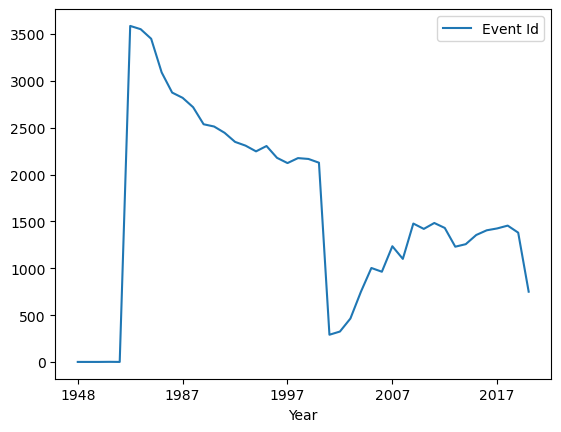

In [65]:
# Draw the line chart that shows the number of event occur each year
annual_aviation_event.plot(x='Year', y='Event Id')
plt.show()

In [66]:
# show the year that has the highest event occur
print(annual_aviation_event.sort_values(by=['Event Id'], ascending = False).head(1))

   Year  Event Id
5  1982      3585


So the year that has the highest number of events is 1982, which 3585 cases events occur.

(3):

In [67]:
# count the number of accident and incident in the dataframe
Investigation_count = new_aviation_df['Investigation Type'].value_counts()

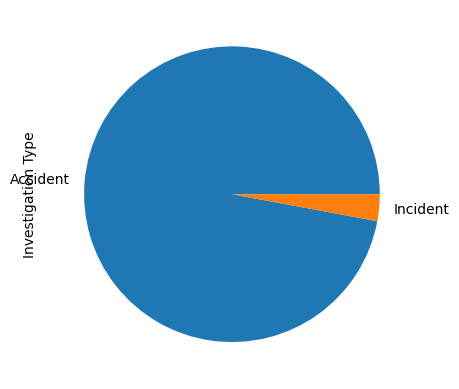

In [68]:
# use pie chart to shows the porportion of incident and accident
Investigation_count.plot(kind='pie')
plt.show()

In [69]:
# show the exact proportion of accident and incident
Accident = Investigation_count['Accident']
Incident = Investigation_count['Incident']
print('the proportion of accident is ' + str(Accident/(Incident+Accident)*100) + ' %')
print('the proportion of incident is ' + str(Incident/(Incident+Accident)*100) + ' %')

the proportion of accident is 97.0774333816479 %
the proportion of incident is 2.9225666183521017 %


The result shows that accident has much greater proportion than incident. So when an aviation event occurs, it's more likely to be an accident instead of an incident.

(4):

In [70]:
# make an dataframe that record the number of event occur with each aircraft make, only shows top 10
aircraft_make_count = new_aviation_df['Make'].value_counts().head(10)

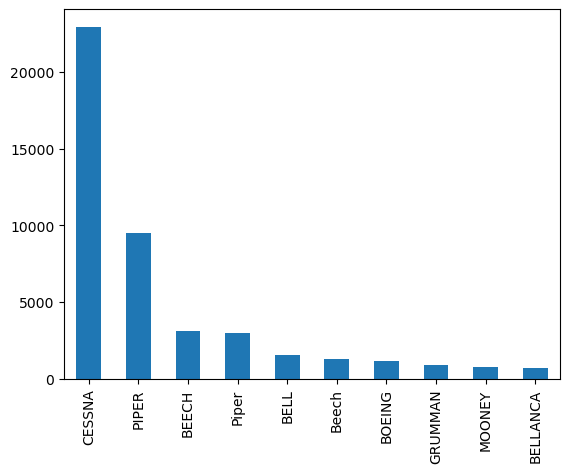

In [71]:
# draw a bar graph that shows the number of event happened with top 10 aircraft makes
aircraft_make_count.plot(kind='bar')
plt.show()

Cessna has the most events. This means that a Cessna is the most likely one to create an aviation event. 

(5):

In [72]:
# select dataframe that only has boeing 737's event
Boeing_737_event = new_aviation_df.loc[(new_aviation_df['Make'] == 'Boeing') & (new_aviation_df['Model'] == '737')]

In [73]:
# add a new column year, and creat a new dataframe that only contains year and numbers of Event Id, group by year
Boeing_737_event_annual = Boeing_737_event.filter(items=['Event Id', 'Event Date'])
Boeing_737_event_annual['Year'] = Boeing_737_event_annual['Event Date'].dt.strftime('%Y')
Boeing_737_event_annual_count = Boeing_737_event_annual.groupby(['Year'], as_index=False)['Event Id'].count()

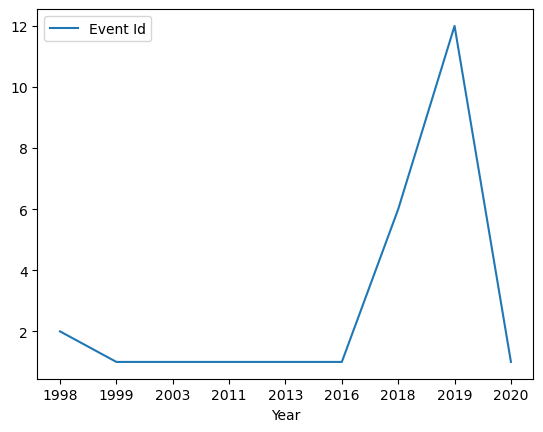

In [74]:
# draw the line chart for boeing 737 event by year
Boeing_737_event_annual_count.plot(x='Year', y='Event Id')
plt.show()

2019 has the most accident for Boeing 737

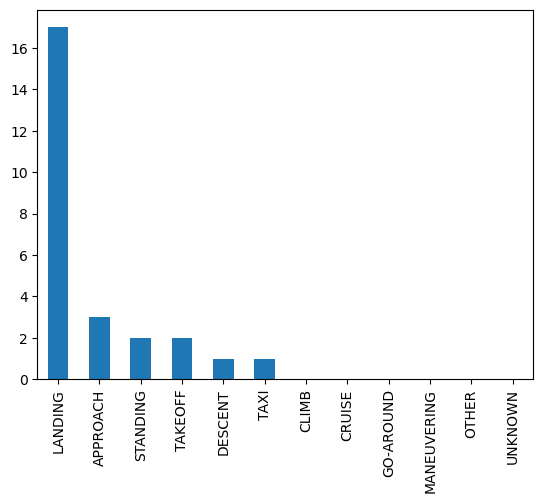

In [75]:
# draw a bar chart to shows the number of accident in each Broad Phase of Flight
Boeing_737_event['Broad Phase of Flight'].value_counts().plot(kind='bar')
plt.show()

So Accidents transpire most during landing.

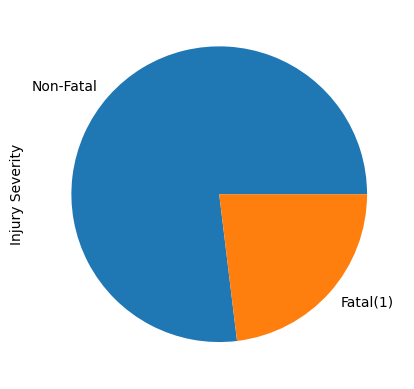

In [76]:
# classify incident as fatal(1), and then draw a pie chart
Boeing_737_event.loc[Boeing_737_event['Injury Severity'] == 'Incident', 'Injury Severity'] = 'Fatal(1)'
Boeing_737_event['Injury Severity'].value_counts().plot(kind='pie')
plt.show()

Most accidents are non-fatal.

(6):

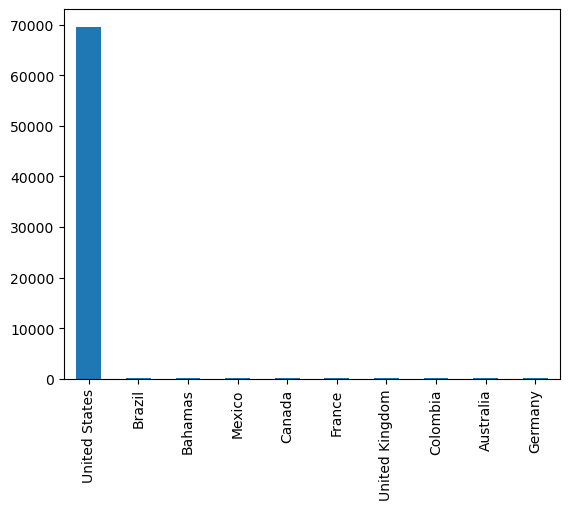

In [77]:
# list countries that has top 10 events happen. Then count which country has the highest number of event happen
new_aviation_df['Country'].value_counts().head(10).plot(kind='bar')
plt.show()

The United States has the highest event happen, and much greater than the second highest event country Brazil.